<a href="https://colab.research.google.com/github/chinmayeearadhyavh/DESEASE-PEDICTION-METRICS/blob/main/disease_prediction_metrics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Disease Prediction: Evaluation Metrics (Confusion Matrix, Precision, Recall, F1)

**Part A** solves the numerical question from the lecture slide by hand-coded formulas.
**Part B** trains models on a real Kaggle dataset (Breast Cancer Wisconsin, Diagnostic), preprocesses it,
and reports accuracy, precision, recall and F1 with plots.

Run in Google Colab: *Runtime > Run all*. All figures are saved in the `visualizations/` folder.

In [36]:
%pip install -q kagglehub

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, roc_auc_score, classification_report)

os.makedirs("visualizations", exist_ok=True)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Part A: The numerical question from the slide

TP=70  TN=100  FP=20  FN=10
Accuracy  = 0.8500  (85.0%)
Precision = 0.7778  (77.8%)
Recall    = 0.8750  (87.5%)
F1-score  = 0.8235  (82.4%)


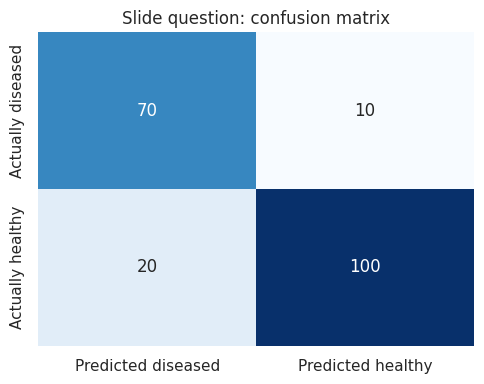

In [ ]:
# 200 patients, 80 actually diseased, model catches 70 of them,
# 20 healthy patients are wrongly flagged as diseased.
TP = 70
FN = 80 - TP            # diseased patients the model missed
FP = 20
TN = (200 - 80) - FP    # healthy patients correctly classified

accuracy  = (TP + TN) / 200
precision = TP / (TP + FP)
recall    = TP / (TP + FN)
f1        = 2 * precision * recall / (precision + recall)

print(f"TP={TP}  TN={TN}  FP={FP}  FN={FN}")
print(f"Accuracy  = {accuracy:.4f}  ({accuracy:.1%})")
print(f"Precision = {precision:.4f}  ({precision:.1%})")
print(f"Recall    = {recall:.4f}  ({recall:.1%})")
print(f"F1-score  = {f1:.4f}  ({f1:.1%})")

cm_slide = np.array([[TP, FN],
                     [FP, TN]])
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm_slide, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Predicted diseased", "Predicted healthy"],
            yticklabels=["Actually diseased", "Actually healthy"])
ax.set_title("Slide question: confusion matrix")
plt.tight_layout()
plt.savefig("visualizations/01_slide_confusion_matrix.png", dpi=150)
plt.show()

## Part B: Real dataset

Dataset: **Breast Cancer Wisconsin (Diagnostic)**, Kaggle handle `uciml/breast-cancer-wisconsin-data`.
If the Kaggle download is not available (for example no internet or Kaggle sign-in problem), the notebook falls back to the
scikit-learn copy of the same UCI data so it still runs. The cell prints which source was used.

In [ ]:
try:
    import kagglehub
    path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
    df = pd.read_csv(os.path.join(path, "data.csv"))
    source = "Kaggle: uciml/breast-cancer-wisconsin-data"
except Exception as e:
    print("Kaggle download failed, using fallback. Reason:", repr(e)[:150])
    from sklearn.datasets import load_breast_cancer
    raw = load_breast_cancer(as_frame=True)
    df = raw.frame.copy()
    df["diagnosis"] = df["target"].map({0: "M", 1: "B"})   # sklearn: 0 = malignant, 1 = benign
    df = df.drop(columns="target")
    source = "scikit-learn copy of the same UCI data (fallback)"

print("Data source:", source)
print("Shape:", df.shape)
df.head()

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
Data source: Kaggle: uciml/breast-cancer-wisconsin-data
Shape: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


### Preprocessing

In [ ]:
# 1. Drop columns that carry no information (id, empty trailing column in the Kaggle file)
df = df.drop(columns=[c for c in ["id", "Unnamed: 32"] if c in df.columns])

# 2. Missing values and duplicates
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
df = df.drop_duplicates()

# 3. Encode the target: Malignant (disease) = 1, Benign (healthy) = 0
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})

X = df.drop(columns="diagnosis")
y = df["diagnosis"]
print("Features:", X.shape[1], "| Samples:", len(df))
print(y.value_counts().rename({1: "Malignant (disease)", 0: "Benign (healthy)"}))

Missing values: 0
Duplicate rows: 0
Features: 30 | Samples: 569
diagnosis
Benign (healthy)       357
Malignant (disease)    212
Name: count, dtype: int64


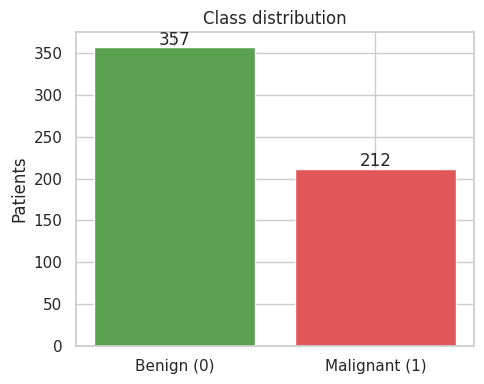

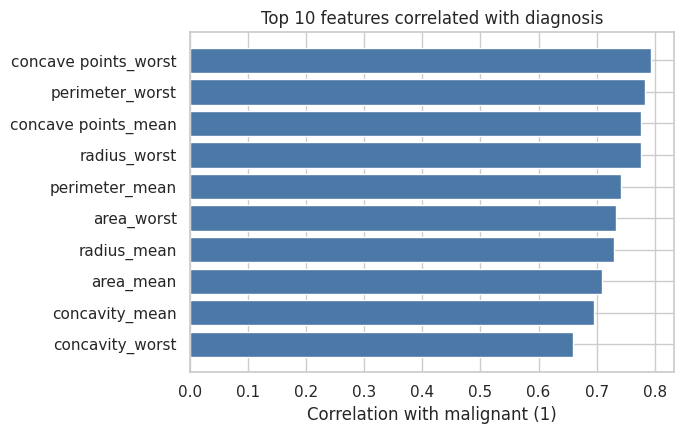

In [ ]:
# Class balance
fig, ax = plt.subplots(figsize=(5, 4))
counts = y.value_counts().sort_index()
ax.bar(["Benign (0)", "Malignant (1)"], counts.values, color=["#59A14F", "#E15759"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 3, str(v), ha="center")
ax.set_title("Class distribution")
ax.set_ylabel("Patients")
plt.tight_layout()
plt.savefig("visualizations/02_class_distribution.png", dpi=150)
plt.show()

# Features most correlated with the diagnosis
corr = X.corrwith(y).sort_values(key=abs, ascending=False).head(10)[::-1]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(corr.index, corr.values, color="#4C78A8")
ax.set_title("Top 10 features correlated with diagnosis")
ax.set_xlabel("Correlation with malignant (1)")
plt.tight_layout()
plt.savefig("visualizations/03_top_correlations.png", dpi=150)
plt.show()

In [ ]:
# Stratified split keeps the same malignant/benign ratio in train and test.
# Scaling happens inside the pipeline, so it is fitted on training data only (no leakage).
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (455, 30) | Test: (114, 30)


### Models and evaluation

In [ ]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows, fitted = [], {}
for name, model in models.items():
    cv_f1 = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1").mean()
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    fitted[name] = model
    rows.append({
        "Model": name,
        "CV F1 (train)": cv_f1,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
results.to_csv("visualizations/model_results.csv")
results

,CV F1 (train),Accuracy,Precision,Recall,F1
Model,,,,,
Logistic Regression,0.9640,0.9649,0.975,0.9286,0.9512
Random Forest,0.9461,0.9737,1.000,0.9286,0.9630


In [ ]:
# Pick the model by cross-validated F1 on the training data (not by test score)
best_name = results["CV F1 (train)"].idxmax()
best = fitted[best_name]
pred = best.predict(X_test)
print("Best model by CV F1:", best_name)
print()
print(classification_report(y_test, pred, target_names=["Benign (healthy)", "Malignant (disease)"], digits=4))

Best model by CV F1: Logistic Regression

                     precision    recall  f1-score   support

   Benign (healthy)     0.9595    0.9861    0.9726        72
Malignant (disease)     0.9750    0.9286    0.9512        42

           accuracy                         0.9649       114
          macro avg     0.9672    0.9573    0.9619       114
       weighted avg     0.9652    0.9649    0.9647       114



### Visualisations

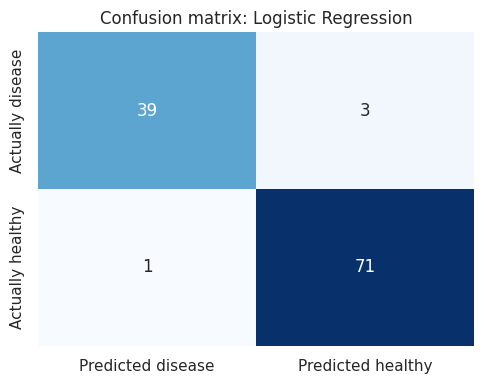

TP=39 TN=71 FP=1 FN=3


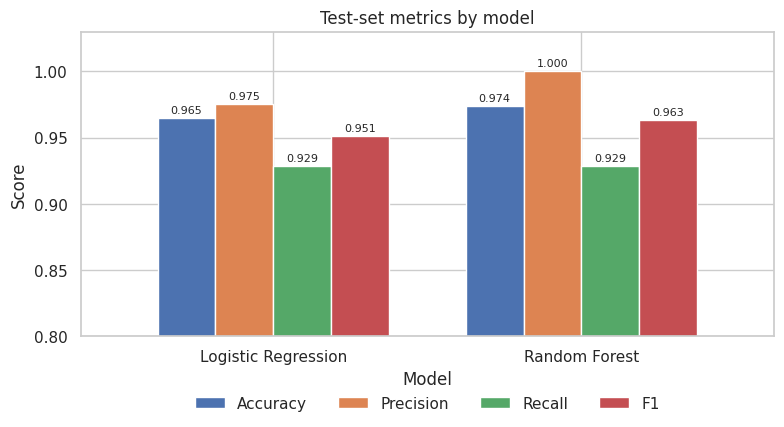

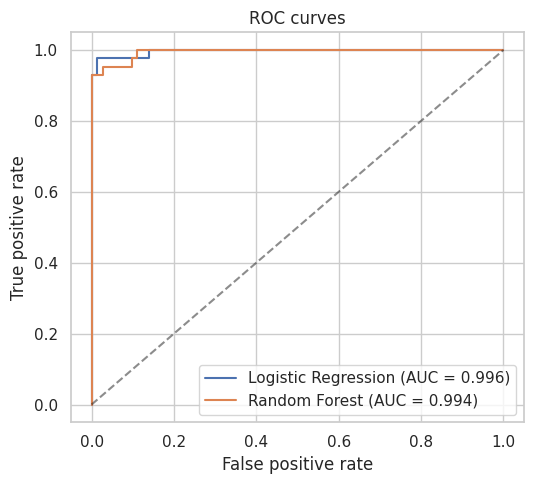

In [ ]:
# Confusion matrix of the best model (same layout as the slide: positive class first)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
cm = np.array([[tp, fn], [fp, tn]])
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Predicted disease", "Predicted healthy"],
            yticklabels=["Actually disease", "Actually healthy"])
ax.set_title(f"Confusion matrix: {best_name}")
plt.tight_layout()
plt.savefig("visualizations/04_model_confusion_matrix.png", dpi=150)
plt.show()
print(f"TP={tp} TN={tn} FP={fp} FN={fn}")

# Metric comparison
metrics = ["Accuracy", "Precision", "Recall", "F1"]
ax = results[metrics].plot(kind="bar", figsize=(8, 4.5), rot=0, width=0.75)
ax.set_ylim(0.8, 1.03)
ax.set_title("Test-set metrics by model")
ax.set_ylabel("Score")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, frameon=False)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8, padding=2)
plt.tight_layout()
plt.savefig("visualizations/05_metric_comparison.png", dpi=150)
plt.show()

# ROC curves
fig, ax = plt.subplots(figsize=(5.5, 5))
for name, model in fitted.items():
    prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.3f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("visualizations/06_roc_curves.png", dpi=150)
plt.show()

### Download the results (Colab)
Zips the `visualizations/` folder so you can download it and commit it to GitHub.

In [ ]:
import shutil
shutil.make_archive("visualizations", "zip", "visualizations")
try:
    from google.colab import files
    files.download("visualizations.zip")
except ImportError:
    print("Not running in Colab. Files are in the 'visualizations' folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>